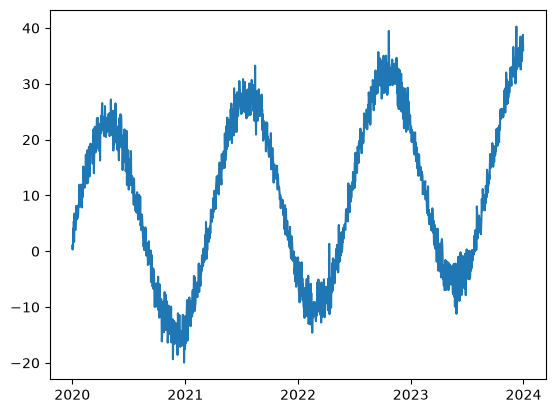

In [11]:
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

years = int(input("How many years is the time series of? "))

start = pd.Timestamp("2020-01-01")
end = start + pd.DateOffset(years=years) - pd.Timedelta(days=1)

dates = pd.date_range(start, end, freq="D")   # handles leap years for you
num_days = len(dates)
t = np.arange(num_days) 

a_raw = np.sin(t / 72)
short_noise = np.random.poisson(2, num_days)
t_scal = t / 100
a_scal = np.random.normal(20, 2, num_days)
a = a_scal * a_raw + t_scal + short_noise

fig, ax = plt.subplots()
ax.plot(dates, a)

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.show()

In [2]:
print(len(a))
print(len(dates))

729


TypeError: object of type 'Timestamp' has no len()

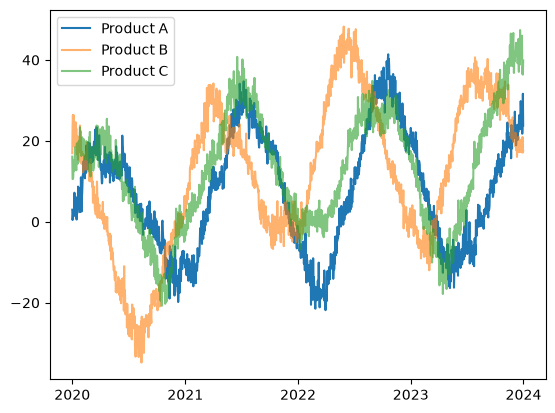

In [17]:
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
import pandas as pd


def ar1_noise(n, phi=0.99, sigma=1.0):
    """Slowly wandering noise. phi near 1 = slower drift."""
    noise = np.zeros(n)
    kicks = np.random.normal(0, sigma, n)
    for i in range(1, n):
        noise[i] = phi * noise[i - 1] + kicks[i]
    return noise

years = int(input("How many years is the time series of? "))

start = pd.Timestamp("2020-01-01")
end = start + pd.DateOffset(years=years) - pd.Timedelta(days=1)
dates = pd.date_range(start, end, freq="D")
num_days = len(dates)
t = np.arange(num_days)

#Basic sine curve
a_raw = np.sin(t / 72)
b_raw = np.cos(t / 72)
c_raw = np.sin(t / 72 + np.pi/6)
trend = t / 100 #Slow increase over time

# Day-to-day noise (equivalent to previosu a_scal)
a_short_noise = np.random.poisson(2, num_days)
b_short_noise = np.random.poisson(2, num_days)
c_short_noise = np.random.poisson(2, num_days)
a_amp_daily = np.random.normal(20, 2, num_days)
b_amp_daily = np.random.normal(20, 2, num_days)
c_amp_daily = np.random.normal(20, 2, num_days)

# Long-term randomness
a_amp_drift = ar1_noise(num_days, phi=0.99, sigma=0.5)      # peaks vary in height
a_baseline_drift = ar1_noise(num_days, phi=0.995, sigma=0.5) # slow wandering offset

b_amp_drift = ar1_noise(num_days, phi=0.99, sigma=0.5)      
b_baseline_drift = ar1_noise(num_days, phi=0.995, sigma=0.5)

c_amp_drift = ar1_noise(num_days, phi=0.99, sigma=0.5)     
c_baseline_drift = ar1_noise(num_days, phi=0.995, sigma=0.5)

a = (a_amp_daily + a_amp_drift) * a_raw + trend + a_baseline_drift + a_short_noise
b = (b_amp_daily + b_amp_drift) * b_raw + trend + b_baseline_drift + b_short_noise
c = (c_amp_daily + c_amp_drift) * c_raw + trend + c_baseline_drift + c_short_noise

fig, ax = plt.subplots()
ax.plot(dates, a, label="Product A")
ax.plot(dates, b, label ="Product B",alpha = 0.6)
ax.plot(dates, c, label="Product C", alpha= 0.6)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()